# Data Science Job Market and Skills Demand Analytics
## Data Visualization Case Study

**Student:** Sabbella Vaishnavi 
**Course:** Data Visualization  
**Submission date:** 19 October 2026

### Project overview

This project explores data science job-market trends using two datasets: `data_science_job_posts_2025.csv`, containing job-posting records for 2025, and `DataScience_salaries_2024.csv`, containing salary records covering 2020–2024. The notebook documents dataset attributes, data-quality checks, cleaning and preprocessing, exploratory visualizations, an interactive Plotly chart, an ethical visualization example, and data preparation for the Tableau dashboard.

### Problem statement

The data science job market includes different job titles, seniority levels, industries, work arrangements, locations, required skills, and salary levels. Missing values, duplicate records, inconsistent field values, and differences in salary representations can make comparisons difficult. This project examines how the supplied datasets can be cleaned and visualized to explore job-posting patterns and reported salaries while clearly communicating data limitations.

### Objectives

- Understand the structure, attributes, data types, and data-quality issues in both datasets.
- Clean and prepare the datasets using separate, reproducible preprocessing steps.
- Explore job-posting distributions by job title, seniority level, industry, work arrangement, location, and required skills.
- Analyze salary distributions and year-wise salary patterns using the salary dataset.
- Create visualizations using Python libraries and an interactive Plotly chart, and prepare the job-posting data for a Tableau dashboard.
- Demonstrate how a visualization can mislead and present an ethically corrected alternative.
- Summarize evidence-based observations without claiming that associations establish causation.

**Data sources:**

- `data_science_job_posts_2025.csv` — job-posting dataset for 2025.
- `DataScience_salaries_2024.csv` — salary dataset covering 2020–2024.

**Important:** The two datasets represent different records and reporting periods, so they are analyzed separately rather than treated as a single joined dataset. Missing values are not automatically interpreted as zero. The job-posting dataset's `company_size` and `revenue` fields contain inconsistent values and should not be used to support conclusions until their meanings are verified. Salary values in the job-posting dataset use a euro symbol but do not clearly specify the salary time basis; therefore, they should not be directly compared with the salary dataset's `salary_in_usd` values. Exact duplicate salary records are documented and removed only from the analytical copy, preserving the original dataset.

## 1. Setup and load the original datasets

# Place both CSV files in the same folder as this notebook.
# If your files are stored elsewhere, update the file paths below.

In [8]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plotly is used as an interactive visualization tool.
try:
    import plotly.express as px
    PLOTLY_AVAILABLE = True
except ImportError:
    PLOTLY_AVAILABLE = False
    print("Plotly is not installed. Install it with: pip install plotly")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)

# File paths for the two original datasets
SALARY_PATH = Path("DataScience_salaries_2024.csv")
JOBS_PATH = Path("data_science_job_posts_2025.csv")

# Check that both files exist
if not SALARY_PATH.exists():
    raise FileNotFoundError(
        "Salary dataset not found. Place DataScience_salaries_2024.csv "
        "beside this notebook or update SALARY_PATH."
    )

if not JOBS_PATH.exists():
    raise FileNotFoundError(
        "Job postings dataset not found. Place data_science_job_posts_2025.csv "
        "beside this notebook or update JOBS_PATH."
    )

# Load the original datasets separately
salary_raw = pd.read_csv(SALARY_PATH)
jobs_raw = pd.read_csv(JOBS_PATH)

# Display basic information
print("Salary dataset:", SALARY_PATH.name)
print("Original salary dataset shape:", salary_raw.shape)

print("\nJob postings dataset:", JOBS_PATH.name)
print("Original job postings dataset shape:", jobs_raw.shape)

# Preview the first five rows of each dataset
print("\nSalary dataset preview:")
display(salary_raw.head())

print("\nJob postings dataset preview:")
display(jobs_raw.head())

Salary dataset: DataScience_salaries_2024.csv
Original salary dataset shape: (14838, 11)

Job postings dataset: data_science_job_posts_2025.csv
Original job postings dataset shape: (944, 13)

Salary dataset preview:


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2021,MI,FT,Data Scientist,30400000,CLP,40038,CL,100,CL,L
1,2021,MI,FT,BI Data Analyst,11000000,HUF,36259,HU,50,US,L
2,2020,MI,FT,Data Scientist,11000000,HUF,35735,HU,50,HU,L
3,2021,MI,FT,ML Engineer,8500000,JPY,77364,JP,50,JP,S
4,2022,SE,FT,Lead Machine Learning Engineer,7500000,INR,95386,IN,50,IN,L



Job postings dataset preview:


,job_title,seniority_level,status,company,location,post_date,headquarter,industry,ownership,company_size,revenue,salary,skills
0,data scientist,senior,hybrid,company_003,"Grapevine, TX . Hybrid",17 days ago,"Bentonville, AR, US",Retail,Public,€352.44B,Public,"€100,472 - €200,938","['spark', 'r', 'python', 'scala', 'machine lea..."
1,data scientist,lead,hybrid,company_005,"Fort Worth, TX . Hybrid",15 days ago,"Detroit, MI, US",Manufacturing,Public,"155,030",€51.10B,"€118,733","['spark', 'r', 'python', 'sql', 'machine learn..."
2,data scientist,senior,on-site,company_007,"Austin, TX . Toronto, Ontario, Canada . Kirkla...",a month ago,"Redwood City, CA, US",Technology,Public,"25,930",€33.80B,"€94,987 - €159,559","['aws', 'git', 'python', 'docker', 'sql', 'mac..."
3,data scientist,senior,hybrid,company_008,"Chicago, IL . Scottsdale, AZ . Austin, TX . Hy...",8 days ago,"San Jose, CA, US",Technology,Public,"34,690",€81.71B,"€112,797 - €194,402","['sql', 'r', 'python']"
4,data scientist,NaN,on-site,company_009,On-site,3 days ago,"Stamford, CT, US",Finance,Private,"1,800",Private,"€114,172 - €228,337",[]


## 2. Dataset description and initial data-quality assessment

In [10]:

# ============================================================
# 2. UNDERSTAND THE DATASET STRUCTURE AND DATA QUALITY
# ============================================================

# -------------------- SALARY DATASET --------------------

print("=" * 60)
print("SALARY DATASET")
print("=" * 60)

print("Rows:", len(salary_raw))
print("Columns:", len(salary_raw.columns))

print("\nColumn names and data types:")

display(pd.DataFrame({
    "column": salary_raw.columns,
    "dtype": [str(salary_raw[c].dtype) for c in salary_raw.columns],
    "missing_count": [salary_raw[c].isna().sum() for c in salary_raw.columns],
    "missing_percent": [
        round(salary_raw[c].isna().mean() * 100, 2)
        for c in salary_raw.columns
    ]
}))

print("\nUnique job titles:", salary_raw["job_title"].nunique())

print(
    "Reporting years:",
    sorted(salary_raw["work_year"].dropna().unique())
)

print("Exact duplicate rows:", salary_raw.duplicated().sum())

print("\nRecords by work year:")

display(
    salary_raw["work_year"]
    .value_counts()
    .sort_index()
    .rename_axis("Work Year")
    .reset_index(name="Records")
)


# -------------------- JOB POSTINGS DATASET --------------------

print("\n" + "=" * 60)
print("JOB POSTINGS DATASET")
print("=" * 60)

print("Rows:", len(jobs_raw))
print("Columns:", len(jobs_raw.columns))

print("\nColumn names and data types:")

display(pd.DataFrame({
    "column": jobs_raw.columns,
    "dtype": [str(jobs_raw[c].dtype) for c in jobs_raw.columns],
    "missing_count": [jobs_raw[c].isna().sum() for c in jobs_raw.columns],
    "missing_percent": [
        round(jobs_raw[c].isna().mean() * 100, 2)
        for c in jobs_raw.columns
    ]
}))


# -------------------- CHECK REQUIRED COLUMNS --------------------

required_salary_columns = {
    "work_year",
    "experience_level",
    "employment_type",
    "job_title",
    "salary_in_usd",
    "company_location",
    "remote_ratio"
}

required_jobs_columns = {
    "job_title",
    "seniority_level",
    "industry",
    "location",
    "skills"
}

missing_salary_columns = required_salary_columns - set(salary_raw.columns)
missing_jobs_columns = required_jobs_columns - set(jobs_raw.columns)

if missing_salary_columns:
    raise ValueError(
        f"Salary dataset columns missing: {sorted(missing_salary_columns)}"
    )
else:
    print("\nSalary dataset column check: PASSED")

if missing_jobs_columns:
    raise ValueError(
        f"Job-postings dataset columns missing: {sorted(missing_jobs_columns)}"
    )
else:
    print("Job-postings dataset column check: PASSED")


# -------------------- JOB TITLE ANALYSIS --------------------

print("\nTop 10 job titles in the job-postings dataset:")

display(
    jobs_raw["job_title"]
    .value_counts()
    .head(10)
    .rename_axis("Job Title")
    .reset_index(name="Records")
)


# -------------------- SENIORITY ANALYSIS --------------------

print("\nJob postings by seniority level:")

display(
    jobs_raw["seniority_level"]
    .value_counts(dropna=False)
    .rename_axis("Seniority Level")
    .reset_index(name="Records")
)


# -------------------- INDUSTRY ANALYSIS --------------------

print("\nTop 10 industries in the job-postings dataset:")

display(
    jobs_raw["industry"]
    .value_counts()
    .head(10)
    .rename_axis("Industry")
    .reset_index(name="Records")
)


# -------------------- DATA QUALITY SUMMARY --------------------

print("\n" + "=" * 60)
print("DATA QUALITY SUMMARY")
print("=" * 60)

print(
    "Missing values in salary dataset:",
    int(salary_raw.isna().sum().sum())
)

print(
    "Missing values in job-postings dataset:",
    int(jobs_raw.isna().sum().sum())
)

print(
    "Duplicate rows in salary dataset:",
    int(salary_raw.duplicated().sum())
)

print(
    "Duplicate rows in job-postings dataset:",
    int(jobs_raw.duplicated().sum())
)

print("\nDataset inspection completed successfully.")


SALARY DATASET
Rows: 14838
Columns: 11

Column names and data types:


,column,dtype,missing_count,missing_percent
0,work_year,int64,0,0.0
1,experience_level,object,0,0.0
2,employment_type,object,0,0.0
3,job_title,object,0,0.0
4,salary,int64,0,0.0
5,salary_currency,object,0,0.0
6,salary_in_usd,int64,0,0.0
7,employee_residence,object,0,0.0
8,remote_ratio,int64,0,0.0
9,company_location,object,0,0.0



Unique job titles: 153
Reporting years: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
Exact duplicate rows: 5711

Records by work year:


,Work Year,Records
0,2020,75
1,2021,218
2,2022,1652
3,2023,8519
4,2024,4374



JOB POSTINGS DATASET
Rows: 944
Columns: 13

Column names and data types:


...


Job postings by seniority level:


,Seniority Level,Records
0,senior,630
1,lead,116
2,midlevel,113
3,NaN,60
4,junior,25



Top 10 industries in the job-postings dataset:


,Industry,Records
0,Technology,582
1,Finance,127
2,Retail,110
3,Healthcare,83
4,Education,19
5,Energy,12
6,Manufacturing,7
7,Logistics,4



DATA QUALITY SUMMARY
Missing values in salary dataset: 0
Missing values in job-postings dataset: 383
Duplicate rows in salary dataset: 5711
Duplicate rows in job-postings dataset: 0

Dataset inspection completed successfully.


### Data quality decisions

- **Missing values are not replaced with zero.** Missing job titles, seniority levels, locations, or other attributes are treated as unknown or unavailable, not as zero or as evidence that a category does not exist.
- **Salary values are interpreted carefully.** The salary dataset's `salary_in_usd` column is used for salary comparisons because it provides a common currency. The job-postings dataset's `salary` field is stored as text and may have a different or unspecified reporting basis, so it is not directly compared with `salary_in_usd`.
- **The datasets are analyzed separately.** The salary dataset covers 2020–2024, while the job-postings dataset represents 2025 postings. Their records are not combined into a single trend because their time periods, structures, and measures differ.
- **Exact duplicate records are identified and reported.** Duplicate rows are removed from an analytical copy only when justified and documented. The original datasets are preserved to maintain data traceability.
- **Inconsistent and unclear categories are checked before analysis.** Fields such as `company_size` and `revenue` are inspected for inconsistent or unexpected values before they are used in visualizations.
- **Cleaning decisions are documented.** Any excluded records, missing-value handling, category standardization, or derived variables are recorded so that the analysis remains transparent and reproducible.

In [11]:

# Create separate working copies of both datasets
salary_df = salary_raw.copy()
jobs_df = jobs_raw.copy()

# --------------------------------------------------
# 1. Normalize text fields
# --------------------------------------------------

for col in salary_df.select_dtypes(include=["object", "string"]).columns:
    salary_df[col] = salary_df[col].astype("string").str.strip()

for col in jobs_df.select_dtypes(include=["object", "string"]).columns:
    jobs_df[col] = jobs_df[col].astype("string").str.strip()

# --------------------------------------------------
# 2. Report exact duplicates
# --------------------------------------------------

salary_duplicate_count = int(salary_df.duplicated().sum())
jobs_duplicate_count = int(jobs_df.duplicated().sum())

print("Salary dataset exact duplicates:", salary_duplicate_count)
print("Job postings dataset exact duplicates:", jobs_duplicate_count)

# Remove exact duplicate rows from the working copies only
salary_df = salary_df.drop_duplicates().copy()
jobs_df = jobs_df.drop_duplicates().copy()

print("\nDuplicates removed from salary dataset:", salary_duplicate_count)
print("Duplicates removed from job postings dataset:", jobs_duplicate_count)

# --------------------------------------------------
# 3. Handle missing values without replacing them
# --------------------------------------------------

print("\nMissing values after duplicate removal")

print("\nSalary dataset:")
print(salary_df.isna().sum()[salary_df.isna().sum() > 0])

print("\nJob postings dataset:")
print(jobs_df.isna().sum()[jobs_df.isna().sum() > 0])

# --------------------------------------------------
# 4. Convert salary fields to numeric where appropriate
# --------------------------------------------------

# Salary dataset: salary_in_usd should be numeric
salary_df["salary_in_usd"] = pd.to_numeric(
    salary_df["salary_in_usd"], errors="coerce"
)

# Job postings dataset: preserve the original salary text
jobs_df["salary_original"] = jobs_df["salary"].astype("string").str.strip()

# Extract a numeric amount for exploratory analysis.
# This does not establish the currency or pay period.
jobs_df["salary_numeric"] = pd.to_numeric(
    jobs_df["salary_original"]
    .str.replace(r"[^\d.,-]", "", regex=True)
    .str.replace(",", "", regex=False),
    errors="coerce"
)

print("\nSalary values that could not be parsed:")
print("Salary dataset:", int(salary_df["salary_in_usd"].isna().sum()))
print("Job postings dataset:", int(jobs_df["salary_numeric"].isna().sum()))

# --------------------------------------------------
# 5. Check the reporting periods
# --------------------------------------------------

print("\nSalary dataset work years:")
print(sorted(salary_df["work_year"].dropna().unique()))

print("\nJob postings post-date examples:")
print(jobs_df["post_date"].head())

# Convert post_date to datetime in a separate column.
# Unparseable dates remain missing rather than being guessed.
jobs_df["post_date_parsed"] = pd.to_datetime(
    jobs_df["post_date"], errors="coerce"
)

print(
    "\nJob posting dates that could not be parsed:",
    int(jobs_df["post_date_parsed"].isna().sum())
)

# --------------------------------------------------
# 6. Summary of cleaned working copies
# --------------------------------------------------

print("\nCleaned salary dataset shape:", salary_df.shape)
print("Cleaned job postings dataset shape:", jobs_df.shape)

print("\nSalary dataset preview:")
display(salary_df.head())

print("\nJob postings dataset preview:")
display(jobs_df.head())


Salary dataset exact duplicates: 5711
Job postings dataset exact duplicates: 0

Duplicates removed from salary dataset: 5711
Duplicates removed from job postings dataset: 0

Missing values after duplicate removal

Salary dataset:
Series([], dtype: int64)

Job postings dataset:
job_title            3
seniority_level     60
status             256
location             2
ownership           47
revenue             15
dtype: int64

Salary values that could not be parsed:
Salary dataset: 0
Job postings dataset: 594

Salary dataset work years:
[np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]

Job postings post-date examples:
0    17 days ago
1    15 days ago
2    a month ago
3     8 days ago
4     3 days ago
Name: post_date, dtype: string

Job posting dates that could not be parsed: 944

Cleaned salary dataset shape: (9127, 11)
Cleaned job postings dataset shape: (944, 16)

Salary dataset preview:


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2021,MI,FT,Data Scientist,30400000,CLP,40038,CL,100,CL,L
1,2021,MI,FT,BI Data Analyst,11000000,HUF,36259,HU,50,US,L
2,2020,MI,FT,Data Scientist,11000000,HUF,35735,HU,50,HU,L
3,2021,MI,FT,ML Engineer,8500000,JPY,77364,JP,50,JP,S
4,2022,SE,FT,Lead Machine Learning Engineer,7500000,INR,95386,IN,50,IN,L



Job postings dataset preview:


,job_title,seniority_level,status,company,location,post_date,headquarter,industry,ownership,company_size,revenue,salary,skills,salary_original,salary_numeric,post_date_parsed
0,data scientist,senior,hybrid,company_003,"Grapevine, TX . Hybrid",17 days ago,"Bentonville, AR, US",Retail,Public,€352.44B,Public,"€100,472 - €200,938","['spark', 'r', 'python', 'scala', 'machine lea...","€100,472 - €200,938",<NA>,NaT
1,data scientist,lead,hybrid,company_005,"Fort Worth, TX . Hybrid",15 days ago,"Detroit, MI, US",Manufacturing,Public,"155,030",€51.10B,"€118,733","['spark', 'r', 'python', 'sql', 'machine learn...","€118,733",118733,NaT
2,data scientist,senior,on-site,company_007,"Austin, TX . Toronto, Ontario, Canada . Kirkla...",a month ago,"Redwood City, CA, US",Technology,Public,"25,930",€33.80B,"€94,987 - €159,559","['aws', 'git', 'python', 'docker', 'sql', 'mac...","€94,987 - €159,559",<NA>,NaT
3,data scientist,senior,hybrid,company_008,"Chicago, IL . Scottsdale, AZ . Austin, TX . Hy...",8 days ago,"San Jose, CA, US",Technology,Public,"34,690",€81.71B,"€112,797 - €194,402","['sql', 'r', 'python']","€112,797 - €194,402",<NA>,NaT
4,data scientist,<NA>,on-site,company_009,On-site,3 days ago,"Stamford, CT, US",Finance,Private,"1,800",Private,"€114,172 - €228,337",[],"€114,172 - €228,337",<NA>,NaT


## 3. Before-and-after data quality summary

In [12]:

# Create a data quality summary for both datasets

quality_summary = pd.DataFrame({
    "Measure": [
        "Original rows",
        "Rows after duplicate removal",
        "Exact duplicate rows",
        "Missing values across all columns",
        "Missing salary values",
        "Missing job title values",
        "Missing seniority level values",
        "Missing location values",
        "Salary values unavailable after numeric parsing",
        "Job posting dates unavailable after parsing"
    ],
    "Salary Dataset": [
        len(salary_raw),
        len(salary_df),
        salary_duplicate_count,
        int(salary_raw.isna().sum().sum()),
        int(salary_df["salary_in_usd"].isna().sum()),
        int(salary_df["job_title"].isna().sum()),
        int(salary_df["experience_level"].isna().sum()),
        int(salary_df["company_location"].isna().sum()),
        int(salary_df["salary_in_usd"].isna().sum()),
        None
    ],
    "Job Postings Dataset": [
        len(jobs_raw),
        len(jobs_df),
        jobs_duplicate_count,
        int(jobs_raw.isna().sum().sum()),
        int(jobs_df["salary_numeric"].isna().sum()),
        int(jobs_df["job_title"].isna().sum()),
        int(jobs_df["seniority_level"].isna().sum()),
        int(jobs_df["location"].isna().sum()),
        int(jobs_df["salary_numeric"].isna().sum()),
        int(jobs_df["post_date_parsed"].isna().sum())
    ]
})

display(quality_summary)


,Measure,Salary Dataset,Job Postings Dataset
0,Original rows,14838.0,944
1,Rows after duplicate removal,9127.0,944
2,Exact duplicate rows,5711.0,0
3,Missing values across all columns,0.0,383
4,Missing salary values,0.0,594
5,Missing job title values,0.0,3
6,Missing seniority level values,0.0,60
7,Missing location values,0.0,2
8,Salary values unavailable after numeric parsing,0.0,594
9,Job posting dates unavailable after parsing,NaN,944


## 4. Select the main indicator for the dashboard story

The main story uses **average salary in USD** as the primary indicator. We use the actual column name `salary_in_usd` from the salary dataset rather than assuming a particular capitalization or suffix. This indicator helps compare salary levels across experience levels, job titles, company locations, and work years. The job-postings dataset is analyzed separately to explore job titles, seniority levels, industries, locations, and in-demand skills.

In [13]:

# 4. Select the main indicator for the dashboard story

# Find the salary indicator using the actual column name.
if "salary_in_usd" not in salary_df.columns:
    raise ValueError("The 'salary_in_usd' column was not found.")

# Ensure salary values are numeric.
salary_df["salary_in_usd"] = pd.to_numeric(
    salary_df["salary_in_usd"], errors="coerce"
)

# Select records with available salary values.
main = salary_df[salary_df["salary_in_usd"].notna()].copy()

MAIN_INDICATOR = "Average salary in USD"

print("Main indicator:", MAIN_INDICATOR)
print("Source column: salary_in_usd")
print("Records:", len(main))
print("Work years:", sorted(main["work_year"].dropna().unique().tolist()))
print(
    "Experience levels:",
    main["experience_level"].dropna().unique().tolist()
)
print(
    "Salary range (USD):",
    int(main["salary_in_usd"].min()),
    "to",
    int(main["salary_in_usd"].max())
)
print("Mean salary (USD):", round(main["salary_in_usd"].mean(), 2))
print("Median salary (USD):", round(main["salary_in_usd"].median(), 2))

display(main.head())


Main indicator: Average salary in USD
Source column: salary_in_usd
Records: 9127
Work years: [2020, 2021, 2022, 2023, 2024]
Experience levels: ['MI', 'SE', 'EN', 'EX']
Salary range (USD): 15000 to 800000
Mean salary (USD): 146752.41
Median salary (USD): 138400.0


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2021,MI,FT,Data Scientist,30400000,CLP,40038,CL,100,CL,L
1,2021,MI,FT,BI Data Analyst,11000000,HUF,36259,HU,50,US,L
2,2020,MI,FT,Data Scientist,11000000,HUF,35735,HU,50,HU,L
3,2021,MI,FT,ML Engineer,8500000,JPY,77364,JP,50,JP,S
4,2022,SE,FT,Lead Machine Learning Engineer,7500000,INR,95386,IN,50,IN,L


## 5. Visualization 1 — Distribution of Data Science Salaries

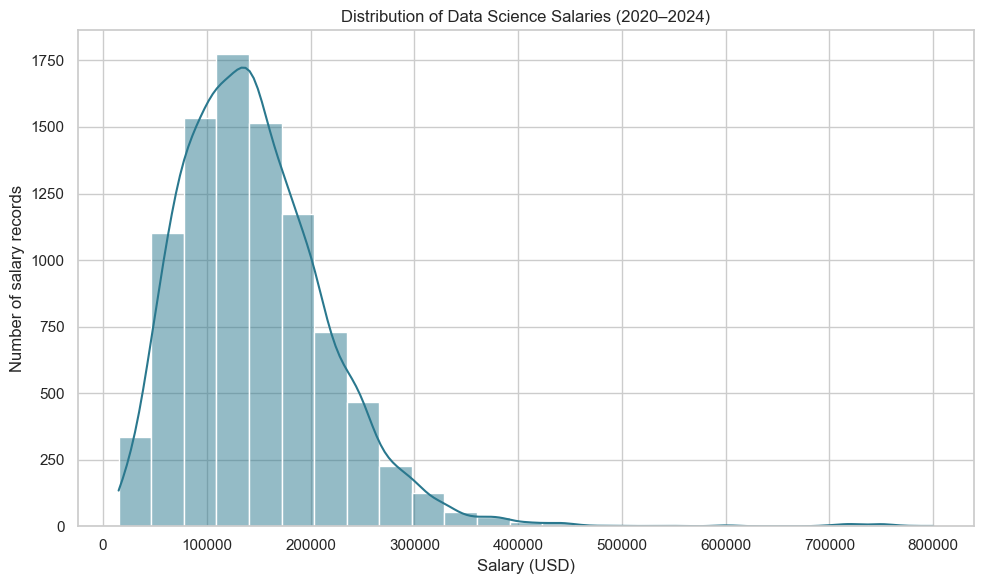

In [14]:

# Visualization 1 — Distribution of Data Science Salaries

plot_data = main["salary_in_usd"].dropna()

if len(plot_data) >= 2:
    fig, ax = plt.subplots(figsize=(10, 6))

    sns.histplot(
        plot_data,
        bins=25,
        kde=True,
        ax=ax,
        color="#2A788E"
    )

    ax.set_title("Distribution of Data Science Salaries (2020–2024)")
    ax.set_xlabel("Salary (USD)")
    ax.set_ylabel("Number of salary records")

    plt.tight_layout()
    plt.show()

else:
    print("Histogram skipped: insufficient numeric observations.")


# Visualization 2 — Highest-paying Data Science Job Titles
# Use the latest available work year in the salary dataset.

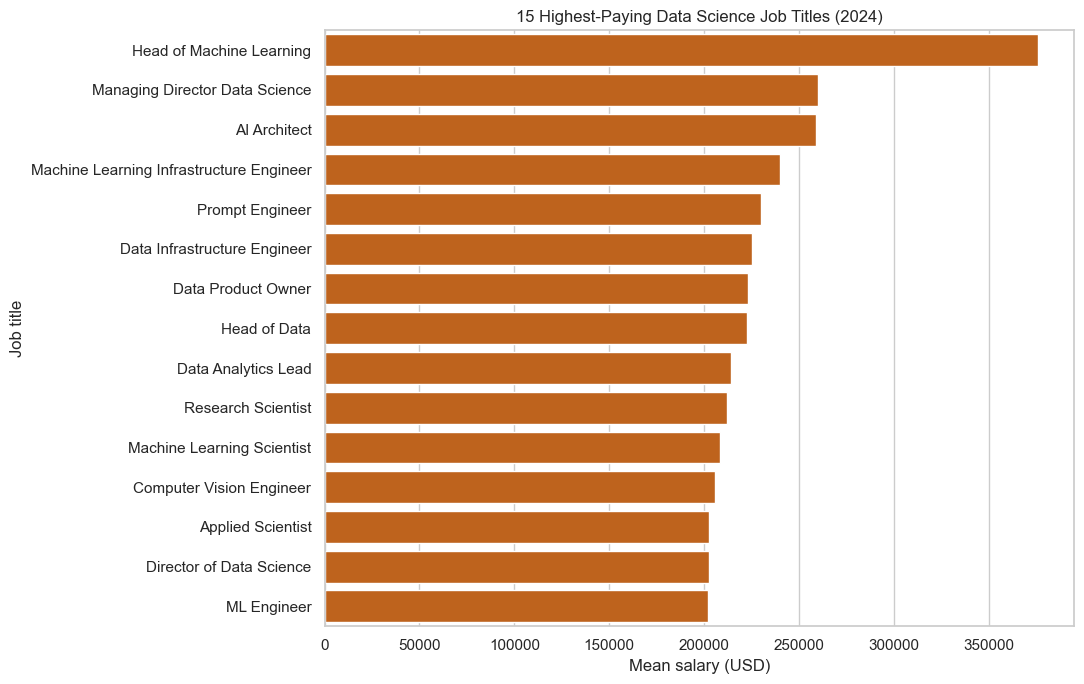

Latest work year used: 2024
Aggregation: mean salary per job title


,job_title,salary_in_usd
75,Head of Machine Learning,376000.000000
88,Managing Director Data Science,260000.000000
0,AI Architect,258753.125000
83,Machine Learning Infrastructure Engineer,240000.000000
89,Prompt Engineer,230010.750000
39,Data Infrastructure Engineer,225205.000000
54,Data Product Owner,223260.000000
74,Head of Data,222750.000000
33,Data Analytics Lead,213900.000000
93,Research Scientist,211831.194175


In [15]:

# Visualization 2 — Highest-paying Data Science Job Titles
# Use the latest available work year in the salary dataset.

if not main.empty and main["work_year"].notna().any():

    latest_year = int(main["work_year"].max())
    latest = main[main["work_year"] == latest_year].copy()

    # Aggregate multiple salary records for each job title using the mean.
    # This aggregation is for comparison and is not a unique-person salary.
    latest_titles = (
        latest.groupby("job_title", as_index=False)["salary_in_usd"]
        .mean()
    )

    latest_titles = latest_titles.dropna(subset=["salary_in_usd"])

    top_titles = (
        latest_titles.sort_values("salary_in_usd", ascending=False)
        .head(15)
    )

    if not top_titles.empty:
        fig, ax = plt.subplots(figsize=(11, 7))

        sns.barplot(
            data=top_titles,
            x="salary_in_usd",
            y="job_title",
            ax=ax,
            color="#D95F02"
        )

        ax.set_title(
            f"15 Highest-Paying Data Science Job Titles ({latest_year})"
        )
        ax.set_xlabel("Mean salary (USD)")
        ax.set_ylabel("Job title")

        plt.tight_layout()
        plt.show()

        print("Latest work year used:", latest_year)
        print("Aggregation: mean salary per job title")
        display(top_titles)

    else:
        print("Job-title ranking skipped: no valid salary values.")

else:
    print("Job-title ranking skipped: no usable work-year information.")


**## 7. Visualization 3 — Historical trend**

**\*\*Question:\*\*** How does the average reported prevalence change across reporting-period start years?

This chart uses multi-year average records only when the selected indicator is a three-year average. The global mean is an unweighted mean across areas with observations; it should not be described as a population-weighted global estimate.

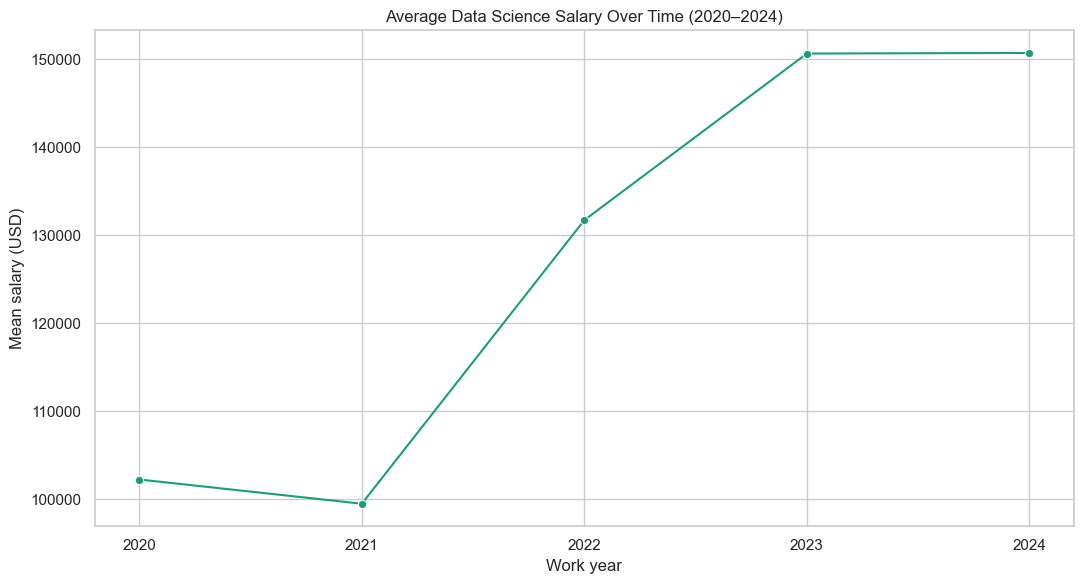

Yearly average salaries:


,work_year,salary_in_usd
0,2020,102250.866667
1,2021,99501.287037
2,2022,131724.043127
3,2023,150644.881261
4,2024,150712.448722


In [16]:

# Visualization 3 — Historical Salary Trend

trend_base = main.copy()

# Keep records with valid work years and numeric salaries.
trend_base = trend_base.dropna(
    subset=["work_year", "salary_in_usd"]
)

# Calculate mean salary for each work year.
trend = (
    trend_base.groupby("work_year", as_index=False)["salary_in_usd"]
    .mean()
    .dropna()
    .sort_values("work_year")
)

if len(trend) >= 2:
    fig, ax = plt.subplots(figsize=(11, 6))

    sns.lineplot(
        data=trend,
        x="work_year",
        y="salary_in_usd",
        marker="o",
        ax=ax,
        color="#1B9E77"
    )

    ax.set_title("Average Data Science Salary Over Time (2020–2024)")
    ax.set_xlabel("Work year")
    ax.set_ylabel("Mean salary (USD)")
    ax.set_xticks(trend["work_year"].astype(int))

    plt.tight_layout()
    plt.show()

    print("Yearly average salaries:")
    display(trend.tail(10))

else:
    print("Trend chart skipped: fewer than two usable work years.")


# Visualization 4 — Job Titles with the Most Salary Records

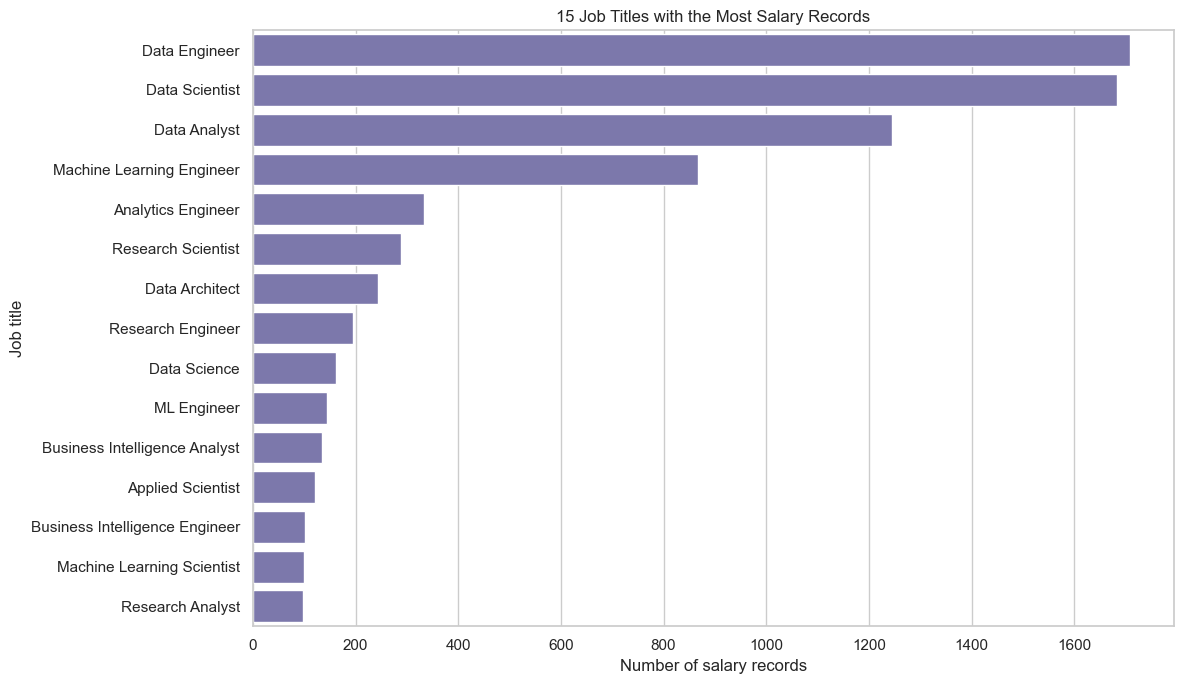

,job_title,Salary records
56,Data Engineer,1709
89,Data Scientist,1684
45,Data Analyst,1245
118,Machine Learning Engineer,867
11,Analytics Engineer,333
145,Research Scientist,288
53,Data Architect,243
144,Research Engineer,194
80,Data Science,162
114,ML Engineer,145


In [18]:

# Visualization 4 — Job Titles with the Most Salary Records

coverage = (
    main.assign(has_salary=main["salary_in_usd"].notna())
    .groupby("job_title", as_index=False)["has_salary"]
    .sum()
    .rename(columns={"has_salary": "Salary records"})
    .sort_values("Salary records", ascending=False)
)

coverage_top = coverage.head(15)

if not coverage_top.empty:
    fig, ax = plt.subplots(figsize=(12, 7))

    sns.barplot(
        data=coverage_top,
        x="Salary records",
        y="job_title",
        ax=ax,
        color="#7570B3"
    )

    ax.set_title("15 Job Titles with the Most Salary Records")
    ax.set_xlabel("Number of salary records")
    ax.set_ylabel("Job title")

    plt.tight_layout()
    plt.show()

    display(coverage_top)

else:
    print("Coverage chart skipped: no job-title records available.")


# Visualization 5 — Salary Distribution Across Popular Job Titles

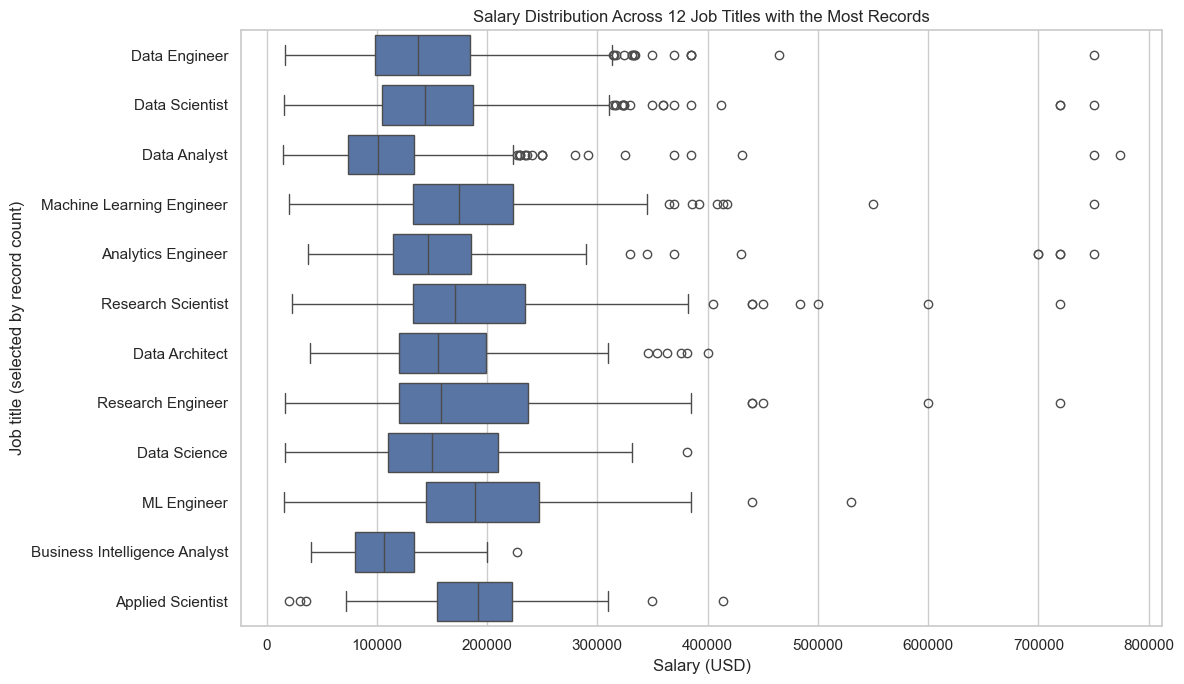

In [19]:

# Visualization 5 — Salary Distribution Across Popular Job Titles

if not main.empty:
    # Select the 12 job titles with the most valid salary observations.
    title_counts = (
        main.groupby("job_title")["salary_in_usd"]
        .count()
        .sort_values(ascending=False)
    )

    selected_titles = title_counts.head(12).index.tolist()

    box_data = main[
        main["job_title"].isin(selected_titles)
    ].dropna(subset=["salary_in_usd"]).copy()

    if box_data["job_title"].nunique() >= 2:
        fig, ax = plt.subplots(figsize=(12, 7))

        sns.boxplot(
            data=box_data,
            x="salary_in_usd",
            y="job_title",
            order=selected_titles,
            ax=ax
        )

        ax.set_title(
            "Salary Distribution Across 12 Job Titles with the Most Records"
        )
        ax.set_xlabel("Salary (USD)")
        ax.set_ylabel("Job title (selected by record count)")

        plt.tight_layout()
        plt.show()

    else:
        print("Boxplot skipped: fewer than two job titles have salary observations.")

else:
    print("Boxplot skipped: no main-indicator data.")


# Visualization 6 — Correlation Heatmap of All Numeric Columns

Numeric columns included:
['work_year', 'salary', 'salary_in_usd', 'remote_ratio']


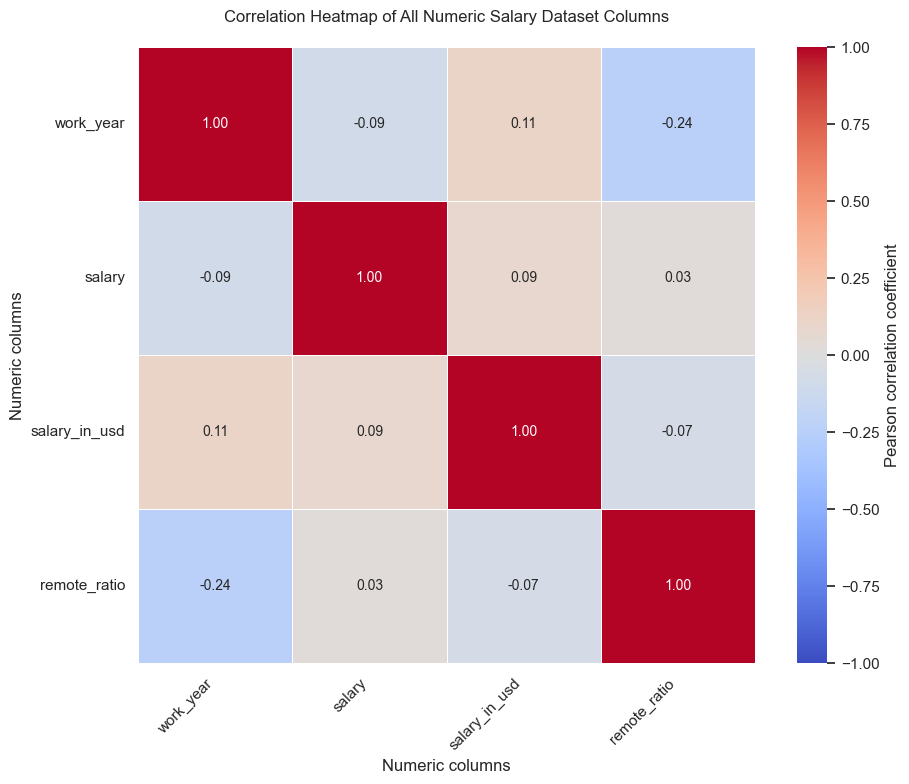


Complete correlation matrix:


,work_year,salary,salary_in_usd,remote_ratio
work_year,1.000000,-0.087881,0.113655,-0.235893
salary,-0.087881,1.000000,0.085644,0.025175
salary_in_usd,0.113655,0.085644,1.000000,-0.065553
remote_ratio,-0.235893,0.025175,-0.065553,1.000000



Valid numeric observations per column:


,Valid observations
work_year,9127
salary,9127
salary_in_usd,9127
remote_ratio,9127


In [22]:

# Visualization 6 — Correlation Heatmap of All Numeric Columns

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --------------------------------------------------
# 1. Prepare the salary dataset
# --------------------------------------------------

# Use the cleaned salary dataset created earlier.
corr_data = salary_df.copy()

# Convert numeric columns explicitly.
numeric_columns = [
    "work_year",
    "salary",
    "salary_in_usd",
    "remote_ratio"
]

for col in numeric_columns:
    if col in corr_data.columns:
        corr_data[col] = pd.to_numeric(
            corr_data[col], errors="coerce"
        )

# Select every available numeric column.
numeric_data = corr_data.select_dtypes(
    include="number"
).copy()

# Remove columns with no variation, since their correlations
# cannot be calculated meaningfully.
constant_columns = [
    col for col in numeric_data.columns
    if numeric_data[col].nunique(dropna=True) <= 1
]

numeric_data = numeric_data.drop(
    columns=constant_columns,
    errors="ignore"
)

print("Numeric columns included:")
print(numeric_data.columns.tolist())

if constant_columns:
    print("\nConstant columns excluded:")
    print(constant_columns)

# --------------------------------------------------
# 2. Calculate the full correlation matrix
# --------------------------------------------------

if numeric_data.shape[1] >= 2:

    corr_matrix = numeric_data.corr(
        method="pearson",
        min_periods=2
    )

    # --------------------------------------------------
    # 3. Display the complete correlation heatmap
    # --------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(max(10, numeric_data.shape[1] * 2),
                 max(8, numeric_data.shape[1] * 1.5))
    )

    sns.heatmap(
        corr_matrix,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        linewidths=0.5,
        square=True,
        annot_kws={"size": 10},
        cbar_kws={
            "label": "Pearson correlation coefficient"
        },
        ax=ax
    )

    ax.set_title(
        "Correlation Heatmap of All Numeric Salary Dataset Columns",
        pad=18
    )
    ax.set_xlabel("Numeric columns")
    ax.set_ylabel("Numeric columns")

    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------
    # 4. Display every row and column of the matrix
    # --------------------------------------------------

    print("\nComplete correlation matrix:")
    display(corr_matrix)

    # --------------------------------------------------
    # 5. Show the number of observations per column
    # --------------------------------------------------

    print("\nValid numeric observations per column:")
    display(numeric_data.count().to_frame(
        name="Valid observations"
    ))

else:
    print(
        "Heatmap skipped: fewer than two numeric columns "
        "with variation are available."
    )


## 11. Visualization 7 — Experience level Vs Salary in USD

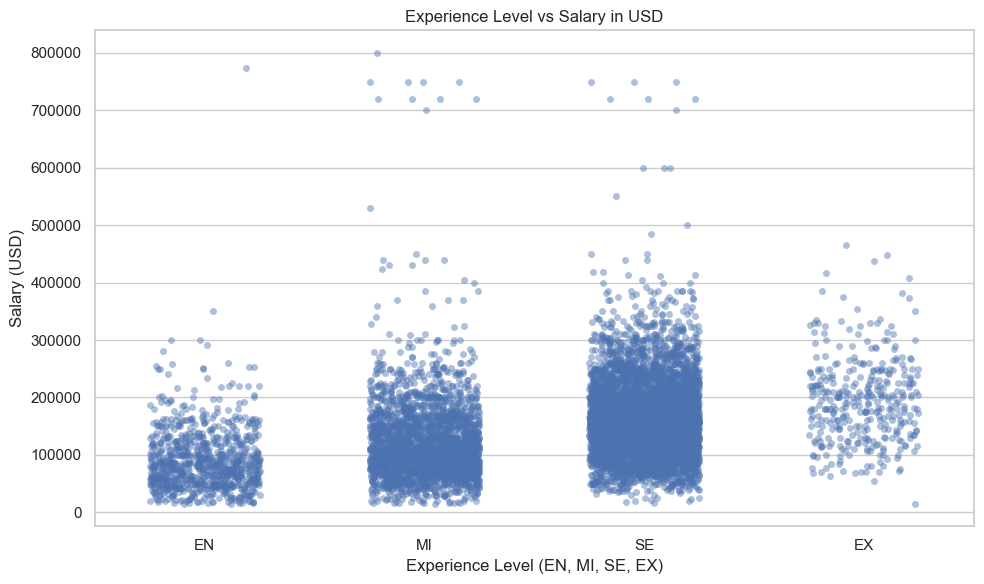

,Number of Records,Average Salary (USD),Median Salary (USD)
experience_level,,,
EN,893,90049.22,80000.0
MI,2466,123633.49,110820.0
SE,5414,163515.72,154000.0
EX,354,194466.08,190250.0


Total observations: 9127
Interpretation note: this plot explores the relationship between experience level and salary; it does not establish causation.


In [23]:

# Find the experience levels available in the dataset
experience_levels = ["EN", "MI", "SE", "EX"]

if "experience_level" in main.columns and "salary_in_usd" in main.columns:

    # Keep records with valid experience levels and salary values
    scatter_base = main[
        main["experience_level"].isin(experience_levels)
        & main["salary_in_usd"].notna()
    ].copy()

    # Map experience levels to an ordered numeric scale
    experience_mapping = {
        "EN": 1,  # Entry-level
        "MI": 2,  # Mid-level
        "SE": 3,  # Senior-level
        "EX": 4   # Executive-level
    }

    scatter_base["experience_number"] = (
        scatter_base["experience_level"].map(experience_mapping)
    )

    if len(scatter_base) >= 3:
        fig, ax = plt.subplots(figsize=(10, 6))

        sns.stripplot(
            data=scatter_base,
            x="experience_level",
            y="salary_in_usd",
            order=experience_levels,
            jitter=0.25,
            alpha=0.45,
            ax=ax
        )

        ax.set_title("Experience Level vs Salary in USD")
        ax.set_xlabel("Experience Level (EN, MI, SE, EX)")
        ax.set_ylabel("Salary (USD)")
        plt.tight_layout()
        plt.show()

        # Display summary statistics for each experience level
        experience_summary = (
            scatter_base.groupby("experience_level")["salary_in_usd"]
            .agg(["count", "mean", "median"])
            .reindex(experience_levels)
        )

        experience_summary.columns = [
            "Number of Records", "Average Salary (USD)", "Median Salary (USD)"
        ]

        display(experience_summary.round(2))

        print("Total observations:", len(scatter_base))
        print(
            "Interpretation note: this plot explores the relationship "
            "between experience level and salary; it does not establish causation."
        )

    else:
        print("The plot could not be created because fewer than three valid records were found.")

else:
    print("Required columns were not found. Check that main contains experience_level and salary_in_usd.")


## 12. Visualization 8 — Data-availability heatmap

**Question:** How complete is indicator coverage across reporting-period start years?

Cells show the share of records with a numeric value for each indicator-period combination. This describes coverage, not indicator values.

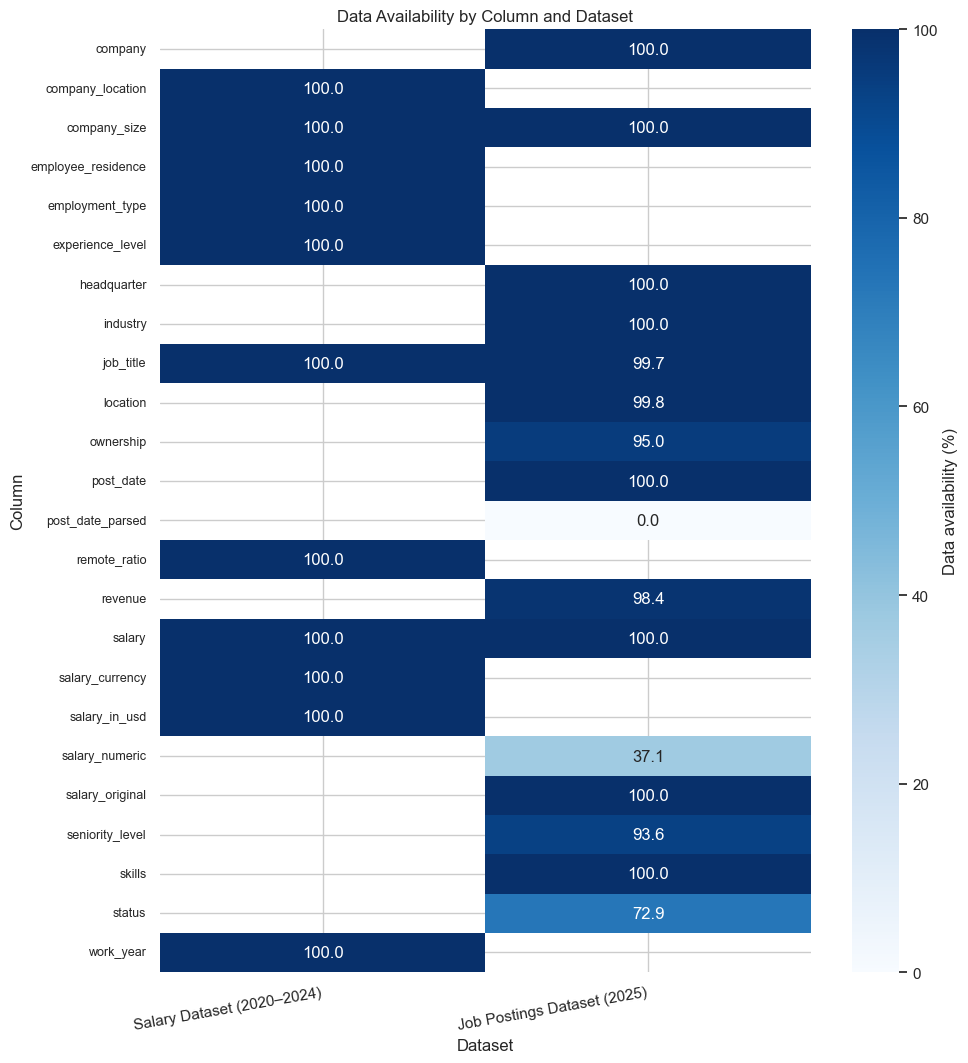

Data availability (%):


,Salary Dataset (2020–2024),Job Postings Dataset (2025)
company,NaN,100.00
company_location,100.0,NaN
company_size,100.0,100.00
employee_residence,100.0,NaN
employment_type,100.0,NaN
experience_level,100.0,NaN
headquarter,NaN,100.00
industry,NaN,100.00
job_title,100.0,99.68
location,NaN,99.79


In [24]:

# Check data availability in both datasets
salary_missing = salary_df.isna().mean()
jobs_missing = jobs_df.isna().mean()

# Combine missing-value percentages into one table
coverage = pd.DataFrame({
    "Salary Dataset (2020–2024)": (1 - salary_missing) * 100,
    "Job Postings Dataset (2025)": (1 - jobs_missing) * 100
})

# Keep all columns from both datasets
coverage = coverage.round(2)

fig, ax = plt.subplots(figsize=(10, max(5, 0.45 * len(coverage))))

sns.heatmap(
    coverage,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Data availability (%)"},
    ax=ax
)

ax.set_title("Data Availability by Column and Dataset")
ax.set_xlabel("Dataset")
ax.set_ylabel("Column")
plt.xticks(rotation=10, ha="right")
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

print("Data availability (%):")
display(coverage)


## 13. Visualization 9 — Boxplot by five-year band

**Question:** Does the distribution across available areas differ across broad time bands?

This groups records by the start year of their reporting period. The bands are descriptive and do not replace careful trend analysis.

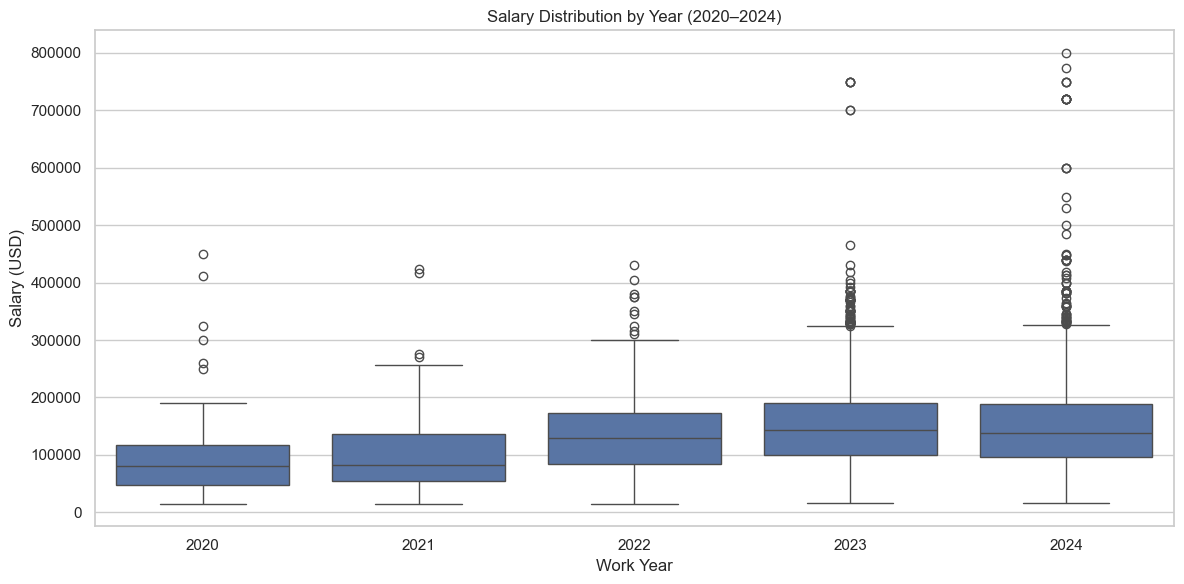

Salary statistics by year:


,count,median,mean,min,max
work_year,,,,,
2020,75,79833.0,102250.87,15000,450000
2021,216,82636.0,99501.29,15000,423000
2022,1113,130000.0,131724.04,15000,430967
2023,4632,143000.0,150644.88,15680,750000
2024,3091,138400.0,150712.45,16666,800000


In [26]:

# Keep records with valid years and salaries
year_data = main[
    main["work_year"].notna()
    & main["salary_in_usd"].notna()
].copy()

if not year_data.empty:

    year_data["work_year"] = year_data["work_year"].astype(int)

    year_order = sorted(year_data["work_year"].unique())

    if len(year_order) >= 2:
        fig, ax = plt.subplots(figsize=(12, 6))

        sns.boxplot(
            data=year_data,
            x="work_year",
            y="salary_in_usd",
            order=year_order,
            ax=ax
        )

        ax.set_title("Salary Distribution by Year (2020–2024)")
        ax.set_xlabel("Work Year")
        ax.set_ylabel("Salary (USD)")
        plt.tight_layout()
        plt.show()

        print("Salary statistics by year:")

        display(
            year_data.groupby("work_year")["salary_in_usd"]
            .agg(["count", "median", "mean", "min", "max"])
            .reindex(year_order)
            .round(2)
        )

    else:
        print("Boxplot skipped: fewer than two distinct years are available.")

else:
    print("Boxplot skipped: no valid salary and year observations.")


## 14. Interactive trend visualization with Plotly

This interactive line chart provides hover details and interactive legend controls for selected areas. If Plotly is unavailable in your environment, install it and rerun this cell.

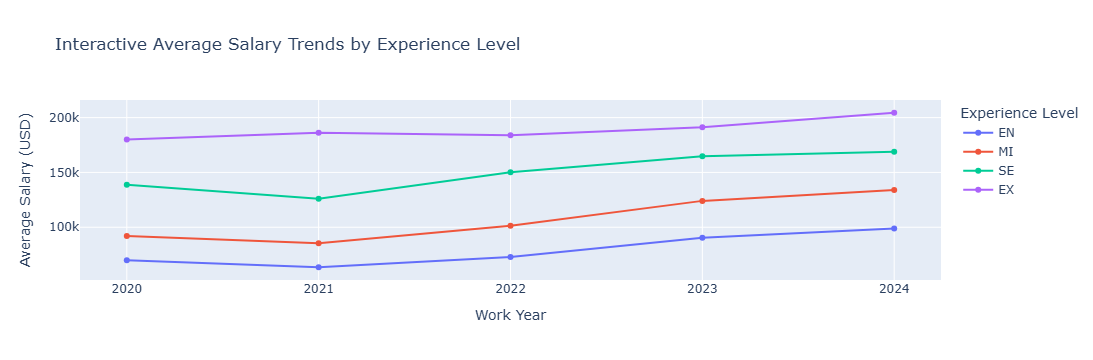

Interactive chart created successfully.


In [27]:

if PLOTLY_AVAILABLE:

    # Keep records with valid work year and salary
    plotly_data = main[
        main["work_year"].notna()
        & main["salary_in_usd"].notna()
        & main["experience_level"].notna()
    ].copy()

    if not plotly_data.empty:

        # Calculate average salary by year and experience level
        plotly_trend = (
            plotly_data.groupby(
                ["work_year", "experience_level"],
                as_index=False
            )["salary_in_usd"]
            .mean()
        )

        # Make the experience levels appear in a logical order
        experience_order = ["EN", "MI", "SE", "EX"]
        plotly_trend["experience_level"] = pd.Categorical(
            plotly_trend["experience_level"],
            categories=experience_order,
            ordered=True
        )

        plotly_trend = plotly_trend.sort_values(
            ["experience_level", "work_year"]
        )

        fig = px.line(
            plotly_trend,
            x="work_year",
            y="salary_in_usd",
            color="experience_level",
            markers=True,
            title="Interactive Average Salary Trends by Experience Level",
            labels={
                "work_year": "Work Year",
                "salary_in_usd": "Average Salary (USD)",
                "experience_level": "Experience Level"
            },
            hover_data={
                "work_year": True,
                "experience_level": True,
                "salary_in_usd": ":,.2f"
            }
        )

        fig.update_layout(
            xaxis=dict(
                tickmode="linear",
                dtick=1
            ),
            legend_title_text="Experience Level"
        )

        fig.show()

        print("Interactive chart created successfully.")

    else:
        print("Plotly trend skipped: no usable salary records.")

else:
    print(
        "Plotly is unavailable. Install it using "
        "!pip install plotly, then rerun the setup cell."
    )


## 15. Ethical visualization — intentionally misleading vs corrected

This section uses the same area-ranking values twice. The intentionally misleading chart truncates the horizontal axis to exaggerate differences; it is clearly labelled as misleading. The corrected chart starts the bar axis at zero.

Use these side-by-side charts in your report/presentation and explain why the first can distort perception.

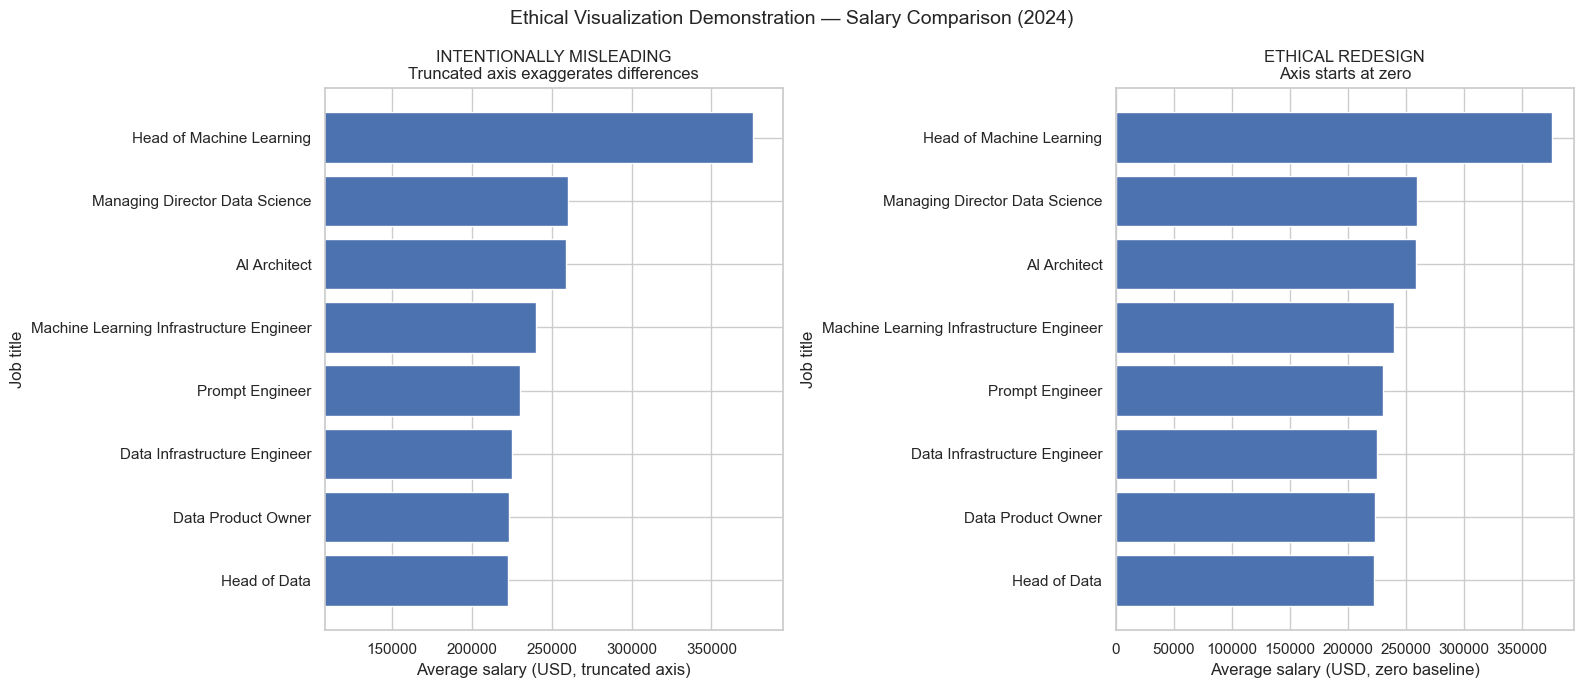

Misleading-chart explanation: the truncated axis makes salary differences appear larger than they are.
Ethical correction: starting the bar axis at zero provides a more proportionate comparison.
Note: These values are average recorded salaries by job title, not guaranteed salaries for every employee.


In [28]:

# Select the 8 highest-paying job titles from the latest available year
latest_year = main["work_year"].max()

ethical_data = (
    main[main["work_year"] == latest_year]
    .groupby("job_title", as_index=False)["salary_in_usd"]
    .mean()
    .sort_values("salary_in_usd", ascending=False)
    .head(8)
    .sort_values("salary_in_usd", ascending=True)
    .copy()
)

if not ethical_data.empty:

    min_value = float(ethical_data["salary_in_usd"].min())
    max_value = float(ethical_data["salary_in_usd"].max())

    # Create a truncated lower bound to exaggerate differences
    truncated_lower = (
        max(0, min_value - 0.75 * (max_value - min_value))
        if max_value > min_value
        else max(0, min_value * 0.8)
    )

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    # INTENTIONALLY MISLEADING: truncated salary axis
    axes[0].barh(
        ethical_data["job_title"],
        ethical_data["salary_in_usd"]
    )
    axes[0].set_xlim(
        truncated_lower,
        max_value * 1.05 if max_value > 0 else 1
    )
    axes[0].set_title(
        "INTENTIONALLY MISLEADING\nTruncated axis exaggerates differences"
    )
    axes[0].set_xlabel("Average salary (USD, truncated axis)")
    axes[0].set_ylabel("Job title")

    # ETHICAL REDESIGN: salary bars start at zero
    axes[1].barh(
        ethical_data["job_title"],
        ethical_data["salary_in_usd"]
    )
    axes[1].set_xlim(0, max_value * 1.05 if max_value > 0 else 1)
    axes[1].set_title(
        "ETHICAL REDESIGN\nAxis starts at zero"
    )
    axes[1].set_xlabel("Average salary (USD, zero baseline)")
    axes[1].set_ylabel("Job title")

    fig.suptitle(
        f"Ethical Visualization Demonstration — Salary Comparison ({int(latest_year)})",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

    print(
        "Misleading-chart explanation: the truncated axis makes salary "
        "differences appear larger than they are."
    )
    print(
        "Ethical correction: starting the bar axis at zero provides a "
        "more proportionate comparison."
    )
    print(
        "Note: These values are average recorded salaries by job title, "
        "not guaranteed salaries for every employee."
    )

else:
    print("Ethical comparison skipped: no usable salary records were found.")


## 16. Key findings from the actual analysis

The next cell summarizes values calculated from the data and charts above. Use these results when writing the report. The findings are descriptive: they do not establish causes, and they apply only to the records and reporting periods shown.

In [29]:

print("KEY FINDINGS — calculated from the current datasets")

# 1. Dataset size and data quality
print("\n1. Dataset and data quality")

print("   Salary dataset source rows:", len(salary_raw))
print("   Salary dataset columns:", salary_raw.shape[1])
print("   Job postings source rows:", len(jobs_raw))
print("   Job postings columns:", jobs_raw.shape[1])

print("   Unique job titles in salary dataset:",
      salary_df["job_title"].nunique())

print("   Exact duplicate salary rows in source:",
      int(salary_raw.duplicated().sum()))

print("   Exact duplicate job posting rows in source:",
      int(jobs_raw.duplicated().sum()))

print("   Missing salary dataset values:",
      int(salary_raw.isna().sum().sum()))

print("   Missing job posting dataset values:",
      int(jobs_raw.isna().sum().sum()))


# 2. Highest-paying job titles in the latest available year
if not main.empty:
    latest_year = int(main["work_year"].max())

    top_paying_jobs = (
        main[main["work_year"] == latest_year]
        .groupby("job_title")["salary_in_usd"]
        .agg(["mean", "count"])
        .sort_values("mean", ascending=False)
        .head(5)
    )

    print(f"\n2. Highest average salaries in {latest_year}")
    print("   Based on job titles with salary records in that year:")

    for job_title, row in top_paying_jobs.iterrows():
        print(
            f"   - {job_title}: ${row['mean']:,.2f} "
            f"(records: {int(row['count'])})"
        )


# 3. Salary trend across years
yearly_trend = (
    main.groupby("work_year")["salary_in_usd"]
    .agg(["mean", "median", "count"])
    .sort_index()
)

if len(yearly_trend) >= 2:
    first = yearly_trend.iloc[0]
    last = yearly_trend.iloc[-1]

    first_year = int(yearly_trend.index[0])
    last_year = int(yearly_trend.index[-1])

    print("\n3. Historical salary trend")
    print(f"   First year ({first_year}) average salary: ${first['mean']:,.2f}")
    print(f"   Latest year ({last_year}) average salary: ${last['mean']:,.2f}")

    if last["mean"] > first["mean"]:
        direction = "increased"
    elif last["mean"] < first["mean"]:
        direction = "decreased"
    else:
        direction = "remained the same"

    print(f"   The recorded average salary {direction} between these years.")

    print("\n   Year-wise salary summary:")
    display(yearly_trend.round(2))


# 4. Most frequently appearing job titles
print("\n4. Most frequently recorded job titles")

top_job_titles = (
    salary_df["job_title"]
    .value_counts()
    .head(5)
)

for title, count in top_job_titles.items():
    print(f"   - {title}: {count} records")


# 5. Most frequently listed skills in job postings
if "skills" in jobs_df.columns:
    skill_counts = (
        jobs_df["skills"]
        .dropna()
        .astype(str)
        .str.lower()
        .str.split(r"[,;|]")
        .explode()
        .str.strip()
    )

    skill_counts = skill_counts[
        skill_counts.ne("") & skill_counts.ne("nan")
    ].value_counts().head(5)

    print("\n5. Most frequently listed skills in job postings")

    if not skill_counts.empty:
        for skill, count in skill_counts.items():
            print(f"   - {skill}: {count} occurrences")
    else:
        print("   No skills could be extracted. Check the skills column format.")


print("\nInterpretation notes:")
print("- Salary comparisons use salary_in_usd from the salary dataset.")
print("- The job postings dataset is analyzed separately.")
print("- Skill counts depend on how skills are separated in the source column.")
print("- Duplicate counts refer to the original source datasets.")
print("- These results describe the available records and do not prove causation.")
print("- Check the charts and dataset definitions before writing conclusions.")


KEY FINDINGS — calculated from the current datasets

1. Dataset and data quality
   Salary dataset source rows: 14838
   Salary dataset columns: 11
   Job postings source rows: 944
   Job postings columns: 13
   Unique job titles in salary dataset: 153
   Exact duplicate salary rows in source: 5711
   Exact duplicate job posting rows in source: 0
   Missing salary dataset values: 0
   Missing job posting dataset values: 383

2. Highest average salaries in 2024
   Based on job titles with salary records in that year:
   - Head of Machine Learning: $376,000.00 (records: 4)
   - Managing Director Data Science: $260,000.00 (records: 1)
   - AI Architect: $258,753.12 (records: 16)
   - Machine Learning Infrastructure Engineer: $240,000.00 (records: 2)
   - Prompt Engineer: $230,010.75 (records: 12)

3. Historical salary trend
   First year (2020) average salary: $102,250.87
   Latest year (2024) average salary: $150,712.45
   The recorded average salary increased between these years.

   Ye

,mean,median,count
work_year,,,
2020,102250.87,79833.0,75
2021,99501.29,82636.0,216
2022,131724.04,130000.0,1113
2023,150644.88,143000.0,4632
2024,150712.45,138400.0,3091



4. Most frequently recorded job titles
   - Data Engineer: 1709 records
   - Data Scientist: 1684 records
   - Data Analyst: 1245 records
   - Machine Learning Engineer: 867 records
   - Analytics Engineer: 333 records

5. Most frequently listed skills in job postings
   - 'machine learning': 428 occurrences
   - 'python': 399 occurrences
   - 'sql': 307 occurrences
   - 'r': 304 occurrences
   - 'python']: 223 occurrences

Interpretation notes:
- Salary comparisons use salary_in_usd from the salary dataset.
- The job postings dataset is analyzed separately.
- Skill counts depend on how skills are separated in the source column.
- Duplicate counts refer to the original source datasets.
- These results describe the available records and do not prove causation.
- Check the charts and dataset definitions before writing conclusions.


## 17. Tableau export — prepare the dashboard data

The dashboard should tell a story: **Where is undernourishment prevalent? How has it changed? What other indicators may be associated with it?**

The export keeps the original value and the proxy flag so the Tableau dashboard can disclose threshold-formatted records. Do not silently treat proxy values as exact measurements.

In [30]:

from pathlib import Path

# Create an output folder for Tableau files
export_folder = Path("tableau_exports")
export_folder.mkdir(exist_ok=True)

# 1. Export the salary dataset
salary_tableau = salary_df.copy()

salary_tableau = salary_tableau.rename(columns={
    "work_year": "Work Year",
    "experience_level": "Experience Level",
    "employment_type": "Employment Type",
    "job_title": "Job Title",
    "salary": "Original Salary",
    "salary_currency": "Salary Currency",
    "salary_in_usd": "Salary in USD",
    "employee_residence": "Employee Residence",
    "remote_ratio": "Remote Ratio",
    "company_location": "Company Location",
    "company_size": "Company Size"
})

salary_path = export_folder / "DataScience_Salaries_Tableau.csv"
salary_tableau.to_csv(salary_path, index=False)

print("Salary dataset exported:", salary_path.resolve())
print("Export shape:", salary_tableau.shape)
display(salary_tableau.head())


# 2. Export the job-postings dataset
jobs_tableau = jobs_df.copy()

jobs_tableau = jobs_tableau.rename(columns={
    "job_title": "Job Title",
    "seniority_level": "Seniority Level",
    "status": "Status",
    "company": "Company",
    "location": "Job Location",
    "post_date": "Post Date",
    "headquarter": "Headquarters",
    "industry": "Industry",
    "ownership": "Ownership",
    "company_size": "Company Size",
    "revenue": "Revenue",
    "salary": "Original Salary",
    "skills": "Skills"
})

jobs_path = export_folder / "DataScience_Job_Postings_Tableau.csv"
jobs_tableau.to_csv(jobs_path, index=False)

print("\nJob postings dataset exported:", jobs_path.resolve())
print("Export shape:", jobs_tableau.shape)
display(jobs_tableau.head())


Salary dataset exported: C:\Users\sabbe\Documents\SEM\SEM5\DV\DV_CaseStudy\review2\tableau_exports\DataScience_Salaries_Tableau.csv
Export shape: (9127, 11)


,Work Year,Experience Level,Employment Type,Job Title,Original Salary,Salary Currency,Salary in USD,Employee Residence,Remote Ratio,Company Location,Company Size
0,2021,MI,FT,Data Scientist,30400000,CLP,40038,CL,100,CL,L
1,2021,MI,FT,BI Data Analyst,11000000,HUF,36259,HU,50,US,L
2,2020,MI,FT,Data Scientist,11000000,HUF,35735,HU,50,HU,L
3,2021,MI,FT,ML Engineer,8500000,JPY,77364,JP,50,JP,S
4,2022,SE,FT,Lead Machine Learning Engineer,7500000,INR,95386,IN,50,IN,L



Job postings dataset exported: C:\Users\sabbe\Documents\SEM\SEM5\DV\DV_CaseStudy\review2\tableau_exports\DataScience_Job_Postings_Tableau.csv
Export shape: (944, 16)


,Job Title,Seniority Level,Status,Company,Job Location,Post Date,Headquarters,Industry,Ownership,Company Size,Revenue,Original Salary,Skills,salary_original,salary_numeric,post_date_parsed
0,data scientist,senior,hybrid,company_003,"Grapevine, TX . Hybrid",17 days ago,"Bentonville, AR, US",Retail,Public,€352.44B,Public,"€100,472 - €200,938","['spark', 'r', 'python', 'scala', 'machine lea...","€100,472 - €200,938",<NA>,NaT
1,data scientist,lead,hybrid,company_005,"Fort Worth, TX . Hybrid",15 days ago,"Detroit, MI, US",Manufacturing,Public,"155,030",€51.10B,"€118,733","['spark', 'r', 'python', 'sql', 'machine learn...","€118,733",118733,NaT
2,data scientist,senior,on-site,company_007,"Austin, TX . Toronto, Ontario, Canada . Kirkla...",a month ago,"Redwood City, CA, US",Technology,Public,"25,930",€33.80B,"€94,987 - €159,559","['aws', 'git', 'python', 'docker', 'sql', 'mac...","€94,987 - €159,559",<NA>,NaT
3,data scientist,senior,hybrid,company_008,"Chicago, IL . Scottsdale, AZ . Austin, TX . Hy...",8 days ago,"San Jose, CA, US",Technology,Public,"34,690",€81.71B,"€112,797 - €194,402","['sql', 'r', 'python']","€112,797 - €194,402",<NA>,NaT
4,data scientist,<NA>,on-site,company_009,On-site,3 days ago,"Stamford, CT, US",Finance,Private,"1,800",Private,"€114,172 - €228,337",[],"€114,172 - €228,337",<NA>,NaT


## 18. Limitations, Recommendations, and Conclusion

### Limitations

- The salary dataset covers 2020–2024, while the job-postings dataset contains postings from 2025. Their different time periods limit direct comparisons.
- Some job-posting fields, including `status`, `seniority_level`, and `ownership`, contain missing values. Visualizations based on these fields reflect only the available observations.
- The salary dataset contains exact duplicate rows. Duplicate records were identified during preprocessing, and analytical results depend on the cleaned dataset used.
- The salary dataset provides `salary_in_usd`, whereas the job-postings dataset stores salary as text. Currency, pay period, and salary-format differences may prevent direct comparison.
- Job titles, experience levels, locations, and skill descriptions may vary in wording and level of detail, affecting grouping and interpretation.
- Average salaries can be influenced by unusually high or low values and by differences in the number and types of records available for each group.
- The datasets describe the available records and may not represent the entire data science job market.
- Correlations and visual associations do not establish causal relationships.

### Recommendations

- Clearly label each visualization with its metric, unit, dataset, and time period.
- Keep missing observations missing rather than replacing them with zero. Document any exclusions or transformations during preprocessing.
- Identify and document duplicate records before removing them, and preserve the original datasets for reference.
- Analyze the salary and job-postings datasets separately unless their currency, pay period, and other relevant definitions can be verified and harmonized.
- Use consistent category labels and carefully inspect skill data before calculating skill frequencies.
- Use appropriate chart types, readable labels, and zero baselines for bar charts showing magnitudes.
- Use interactive Tableau filters to explore job titles, seniority levels, industries, locations, and other relevant categories.
- Interpret differences in average salaries cautiously, considering sample sizes, outliers, and differences in the composition of records.
- Treat dashboard patterns as starting points for further investigation rather than evidence of causes that have not been tested.

### Conclusion

The Data Science Job Market and Skills Demand Analytics project combines data understanding, preprocessing, exploratory analysis, Python visualizations, interactive Plotly charts, and Tableau dashboards to examine salary patterns and job-market skill demand. The salary dataset supports analysis of salary distributions, experience levels, job titles, and historical trends from 2020 to 2024. The separate 2025 job-postings dataset supports exploration of job titles, seniority, industries, locations, company characteristics, and listed skills.

By using multiple visualization techniques and interactive dashboard filters, the project provides a structured way to explore patterns in the available data. However, reliable conclusions depend on careful handling of duplicate records, missing values, salary formats, and differences between datasets. The findings should be interpreted as descriptive insights into the records analyzed rather than definitive statements about the entire job market.

**Before submission:** Run the notebook from the first cell to the last, confirm that all visualizations execute correctly, verify written interpretations against the actual outputs, export the cleaned datasets for Tableau, and save the completed Tableau dashboard as a `.twbx` packaged workbook.